# EECE5554 Final Project — A-GPS Cold First Fix Analysis

Modified plots: GT-anchored time axis (TTFF visible), mean over runs,
time-synced error, matched y-axes.

In [1]:
# Import libraries.
import numpy as np
import csv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path
from rosbags.rosbag2 import Reader
from rosbags.serde import deserialize_cdr
import openpyxl

In [59]:
# Navigate to project root 
try:
    _here = Path(__file__).resolve().parent
    os.chdir(_here.parent)
except NameError:
    if not Path("data").exists() and Path("../data").exists():
        os.chdir("..")
os.makedirs("plots_jh", exist_ok=True)

THRESHOLD = 5.0
WINDOW = 120
ZOOM = 60
TIME_SYNC_WINDOW = 120  # first 100 seconds for time-synced plots

# colors used throughout
C_AGPS = '#27ae60'
C_UNASSISTED = '#e67e22'
C_EKF = '#2980b9'
C_GT = '#95a5a6'

## Data Paths

In [3]:
driving_trials = [
    {"name": "Drive 1 (A-GPS)",      "condition": "agps_on",    "bag": "data/driving/trial1/agps/sensor/trial1",       "phone": "data/driving/trial1/agps/cellphone/RSN Final 2026-04-11 11-05-45.xlsx",       "gt": "data/driving/trial1/agps/ground_truth/Raw Data.csv"},
    {"name": "Drive 1 (Unassisted)", "condition": "unassisted", "bag": "data/driving/trial1/unassisted/sensor/trial1",  "phone": "data/driving/trial1/unassisted/cellphone/RSN Final 2026-04-11 11-26-48.xlsx", "gt": "data/driving/trial1/unassisted/ground_truth/Raw Data.csv"},
    {"name": "Drive 2 (A-GPS)",      "condition": "agps_on",    "bag": "data/driving/trial2/agps/sensor/trial2",       "phone": "data/driving/trial2/agps/cellphone/RSN Final 2026-04-11 11-43-30.xlsx",       "gt": "data/driving/trial2/agps/ground_truth/Raw Data.csv"},
    {"name": "Drive 2 (Unassisted)", "condition": "unassisted", "bag": "data/driving/trial2/unassisted/sensor/trial2",  "phone": "data/driving/trial2/unassisted/cellphone/RSN Final 2026-04-11 12-02-55.xlsx", "gt": "data/driving/trial2/unassisted/ground_truth/Raw Data.csv"},
]

In [4]:
stationary_trials = [
    {"name": "Stat 1 (A-GPS)",      "condition": "agps_on",    "bag": "data/stationary/sensor/trial1",  "phone": "data/stationary/cellphone/agps/RSN Final 2026-04-10 16-23-13.xlsx"},
    {"name": "Stat 2 (Unassisted)", "condition": "unassisted", "bag": "data/stationary/sensor/trial2",  "phone": "data/stationary/cellphone/unassisted/RSN Final 2026-04-10 16-29-28.xlsx"},
    {"name": "Stat 3 (A-GPS)",      "condition": "agps_on",    "bag": "data/stationary/sensor/trial3",  "phone": "data/stationary/cellphone/agps/RSN Final 2026-04-10 16-35-23.xlsx"},
    {"name": "Stat 4 (Unassisted)", "condition": "unassisted", "bag": "data/stationary/sensor/trial4",  "phone": "data/stationary/cellphone/unassisted/RSN Final 2026-04-10 16-41-08.xlsx"},
    {"name": "Stat 5 (A-GPS)",      "condition": "agps_on",    "bag": "data/stationary/sensor/trial5",  "phone": "data/stationary/cellphone/agps/RSN Final 2026-04-10 16-45-45.xlsx"},
    {"name": "Stat 6 (Unassisted)", "condition": "unassisted", "bag": "data/stationary/sensor/trial6",  "phone": "data/stationary/cellphone/unassisted/RSN Final 2026-04-10 16-50-58.xlsx"},
    {"name": "Stat 7 (A-GPS)",      "condition": "agps_on",    "bag": "data/stationary/sensor/trial7",  "phone": "data/stationary/cellphone/agps/RSN Final 2026-04-10 16-55-14.xlsx"},
    {"name": "Stat 8 (Unassisted)", "condition": "unassisted", "bag": "data/stationary/sensor/trial8",  "phone": "data/stationary/cellphone/unassisted/RSN Final 2026-04-10 16-59-09.xlsx"},
    {"name": "Stat 9 (A-GPS)",      "condition": "agps_on",    "bag": "data/stationary/sensor/trial9",  "phone": "data/stationary/cellphone/agps/RSN Final 2026-04-10 17-04-33.xlsx"},
    {"name": "Stat 10 (Unassisted)","condition": "unassisted", "bag": "data/stationary/sensor/trial10", "phone": "data/stationary/cellphone/unassisted/RSN Final 2026-04-10 17-08-31.xlsx"},
]

## Helper Functions

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    r = 6371000.0
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat/2)**2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2
    return r * 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))

In [6]:
def to_meters(lat, lon, ref_lat, ref_lon):
    north = (lat - ref_lat) * 111320.0
    east = (lon - ref_lon) * 111320.0 * np.cos(np.radians(ref_lat))
    return east, north

In [7]:
def load_system_time(file_path):
    """Return the START system time (Unix epoch) for a data file.
    
    For .csv files: reads meta/time.csv in the sibling 'meta' directory.
    For .xlsx files: reads the 'Metadata Time' sheet inside the workbook.
    """
    if file_path.lower().endswith('.xlsx'):
        return _load_system_time_xlsx(file_path)
    else:
        return _load_system_time_csv(file_path)

def _load_system_time_csv(csv_path):
    meta_dir = os.path.join(os.path.dirname(csv_path), "meta")
    time_path = os.path.join(meta_dir, "time.csv")
    if not os.path.isfile(time_path):
        return None
    with open(time_path, 'r') as f:
        reader = csv.reader(f)
        header = [h.strip().strip('"').lower() for h in next(reader)]
        sys_col = next((i for i, h in enumerate(header) if 'system time' == h), None)
        if sys_col is None:
            sys_col = next((i for i, h in enumerate(header) if 'system time' in h and 'text' not in h), None)
        # Positional fallback: col 0=event, 1=experiment time, 2=system time
        if sys_col is None:
            sys_col = 2
        for row in reader:
            try:
                return float(row[sys_col])
            except:
                return None
    return None

def _load_system_time_xlsx(xlsx_path):
    if not os.path.isfile(xlsx_path):
        return None
    try:
        wb = openpyxl.load_workbook(xlsx_path, read_only=True)
        if 'Metadata Time' not in wb.sheetnames:
            wb.close(); return None
        rows = list(wb['Metadata Time'].iter_rows(values_only=True))
        wb.close()
        if len(rows) < 2:
            return None
        # Try header-based lookup first
        header = [str(h).strip().lower() if h is not None else '' for h in rows[0]]
        sys_col = next((i for i, h in enumerate(header) if 'system time' == h), None)
        if sys_col is None:
            sys_col = next((i for i, h in enumerate(header) if 'system time' in h and 'text' not in h), None)
        # Positional fallback: col 0=event, 1=experiment time, 2=system time
        if sys_col is None:
            sys_col = 2
        # Row 1 is the START event
        return float(rows[1][sys_col])
    except:
        return None

## Loading Data

In [8]:
def load_phyphox_csv(path):
    data = []
    with open(path, 'r') as f:
        reader = csv.reader(f)
        header = [h.strip().strip('"').lower() for h in next(reader)]
        t_col, lat_col, lon_col = -1, -1, -1
        for i, h in enumerate(header):
            if 'time' in h: t_col = i
            if 'latitude' in h: lat_col = i
            if 'longitude' in h: lon_col = i
        # Positional fallback if headers are blank/missing
        if t_col == -1 or lat_col == -1 or lon_col == -1:
            t_col, lat_col, lon_col = 0, 1, 2
        for row in reader:
            try:
                t, lat, lon = float(row[t_col]), float(row[lat_col]), float(row[lon_col])
            except: continue
            if abs(lat) < 1 or abs(lon) < 1: continue
            data.append({'t': t, 'lat': lat, 'lon': lon})
    print(f"  loaded {len(data)} pts from {Path(path).name}")
    return data

In [9]:
def load_phyphox_xlsx(path):
    data = []
    wb = openpyxl.load_workbook(path, read_only=True)
    if 'Location' not in wb.sheetnames:
        wb.close(); return data
    rows = list(wb['Location'].iter_rows(values_only=True))
    wb.close()
    if len(rows) < 2: return data
    # Handle possibly blank headers — try named lookup, fall back to positional
    header = [str(h).strip().lower() if h is not None else '' for h in rows[0]]
    t_col, lat_col, lon_col = -1, -1, -1
    for i, h in enumerate(header):
        if 'time' in h: t_col = i
        if 'latitude' in h or 'lat' in h: lat_col = i
        if 'longitude' in h or 'lon' in h: lon_col = i
    if t_col == -1 or lat_col == -1 or lon_col == -1:
        # Positional fallback: col 0=time, 1=lat, 2=lon
        t_col, lat_col, lon_col = 0, 1, 2
    for row in rows[1:]:
        try:
            t, lat, lon = float(row[t_col]), float(row[lat_col]), float(row[lon_col])
        except: continue
        if abs(lat) < 1 or abs(lon) < 1: continue
        data.append({'t': t, 'lat': lat, 'lon': lon})
    print(f"  loaded {len(data)} pts from {Path(path).name}")
    return data

In [10]:
def load_bag(path):
    imu_data, gps_data = [], []
    with Reader(path) as reader:
        imu_conns = [c for c in reader.connections if c.topic == '/imu']
        gps_conns = [c for c in reader.connections if c.topic == '/gps/fix']
        for conn, ts, raw in reader.messages(connections=imu_conns):
            msg = deserialize_cdr(raw, conn.msgtype)
            t = msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9
            imu_data.append({'t': t, 'ax': msg.linear_acceleration.x, 'ay': msg.linear_acceleration.y,
                             'az': msg.linear_acceleration.z, 'gx': msg.angular_velocity.x,
                             'gy': msg.angular_velocity.y, 'gz': msg.angular_velocity.z})
        for conn, ts, raw in reader.messages(connections=gps_conns):
            msg = deserialize_cdr(raw, conn.msgtype)
            t = msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9
            gps_data.append({'t': t, 'lat': msg.latitude, 'lon': msg.longitude,
                             'alt': msg.altitude, 'status': msg.status.status})
    print(f"  bag: {len(imu_data)} imu, {len(gps_data)} gps")
    return imu_data, gps_data

## Extended Kalman Filter

In [11]:
def run_ekf(imu_data, gps_data):
    good_gps = [g for g in gps_data if g['status'] >= 0]
    if len(good_gps) == 0:
        print("  no valid gps fixes"); return []

    ref_lat, ref_lon = good_gps[0]['lat'], good_gps[0]['lon']
    x = np.zeros(5)
    P = np.diag([100, 100, 10, 10, 1.0])

    n_cal = min(100, len(imu_data))
    grav_ax = np.mean([d['ax'] for d in imu_data[:n_cal]]) if n_cal > 0 else 0
    grav_ay = np.mean([d['ay'] for d in imu_data[:n_cal]]) if n_cal > 0 else 0

    events = [('imu', d['t'], d) for d in imu_data] + [('gps', d['t'], d) for d in good_gps]
    events.sort(key=lambda e: e[1])

    output = []
    started = False
    prev_t = None

    for typ, t, d in events:
        if typ == 'imu':
            if prev_t is None: prev_t = t; continue
            dt = t - prev_t; prev_t = t
            if dt <= 0 or dt > 1.0: continue
            ax, ay = d['ax'] - grav_ax, d['ay'] - grav_ay
            hdg = x[4]
            a_e = ax * np.cos(hdg) - ay * np.sin(hdg)
            a_n = ax * np.sin(hdg) + ay * np.cos(hdg)
            F = np.eye(5); F[0,2] = dt; F[1,3] = dt
            x[0] += x[2]*dt + 0.5*a_e*dt**2
            x[1] += x[3]*dt + 0.5*a_n*dt**2
            x[2] += a_e*dt; x[3] += a_n*dt
            x[4] += d['gz']*dt
            x[4] = (x[4] + np.pi) % (2*np.pi) - np.pi
            Q = np.diag([0.5*dt, 0.5*dt, 5.0*dt, 5.0*dt, 0.05*dt])
            P = F @ P @ F.T + Q
        elif typ == 'gps':
            e, n = to_meters(d['lat'], d['lon'], ref_lat, ref_lon)
            if not started:
                x[0]=e; x[1]=n; x[2]=0; x[3]=0; started=True
                output.append({'t': t, 'lat': d['lat'], 'lon': d['lon']}); continue
            z = np.array([e, n])
            H = np.zeros((2,5)); H[0,0]=1; H[1,1]=1
            y = z - H @ x
            R = np.diag([9.0, 9.0])
            S = H @ P @ H.T + R
            K = P @ H.T @ np.linalg.inv(S)
            x = x + K @ y; P = (np.eye(5) - K @ H) @ P
            output.append({'t': t, 'lat': d['lat'], 'lon': d['lon']})
    print(f"  ekf: {len(output)} fused points")
    return output

## Error Computation — Spatial Matching

In [12]:
def compute_errors_spatial(test, gt, test_epoch=None, gt_epoch=None):
    """For each test point, find nearest ground truth point by position (cross-track error).

    If *test_epoch* and *gt_epoch* (Unix start times) are supplied, ``dt``
    is expressed relative to the GT start — matching the convention used by
    ``compute_errors_time_synced`` — so TTFF gaps are visible on a shared
    time axis.  When epochs are unavailable the original behaviour is kept
    (``dt`` relative to the first test point).
    """
    if len(test) == 0 or len(gt) == 0:
        return []
    gt_lat = np.array([g['lat'] for g in gt])
    gt_lon = np.array([g['lon'] for g in gt])
    errors = []
    for p in test:
        dists = np.array([haversine(p['lat'], p['lon'], gt_lat[i], gt_lon[i])
                          for i in range(len(gt_lat))])
        min_err = float(np.min(dists))
        # Compute dt relative to GT start when epochs are available
        if test_epoch is not None and gt_epoch is not None:
            p_abs = test_epoch + p['t']
            dt = p_abs - gt_epoch
        else:
            dt = p['t'] - test[0]['t']
        errors.append({'t': p['t'], 'err': min_err, 'dt': dt})
    return errors

In [ ]:
def compute_errors_time_synced(test, gt, test_epoch, gt_epoch):
    """Match test and ground truth by absolute timestamp (time-synced error).
    
    test_epoch / gt_epoch are the Unix START times from meta/time.csv.
    Each point's absolute time = epoch + point['t'].
    For each test point, find the nearest GT point by absolute time.
    """
    if len(test) == 0 or len(gt) == 0:
        return []
    gt_abs = np.array([gt_epoch + g['t'] for g in gt])
    gt_lat = np.array([g['lat'] for g in gt])
    gt_lon = np.array([g['lon'] for g in gt])
    errors = []
    for p in test:
        p_abs = test_epoch + p['t']
        idx = np.argmin(np.abs(gt_abs - p_abs))
        err = haversine(p['lat'], p['lon'], gt_lat[idx], gt_lon[idx])
        # dt relative to GT start
        dt_start = p_abs - gt_epoch
        errors.append({'t': p['t'], 'err': float(err), 'dt': dt_start})
    return errors

In [14]:
def compute_errors_stationary(data):
    if len(data) == 0: return []
    avg_lat = np.mean([d['lat'] for d in data])
    avg_lon = np.mean([d['lon'] for d in data])
    t0 = data[0]['t']
    return [{'t': d['t'], 'err': haversine(d['lat'], d['lon'], avg_lat, avg_lon),
             'dt': d['t'] - t0} for d in data]

## Convergence Fitting

In [15]:
def fit_curve(errors):
    if len(errors) < 10: return None, None, None
    t = np.array([e['dt'] for e in errors])
    err = np.array([e['err'] for e in errors])
    try:
        guess = [err[0], 0.01, float(np.median(err[-20:]))]
        params, _ = curve_fit(lambda t,a,b,c: a*np.exp(-b*t)+c,
                              t, err, p0=guess, maxfev=5000,
                              bounds=([0,0,0],[1000,10,100]))
        a, b, c = params
        conv_time = -np.log((THRESHOLD - c) / a) / b if (c < THRESHOLD and a > 0 and b > 0) else None
        return params, conv_time, None
    except:
        return None, None, None

## Process Driving Trials

In [16]:
print("=" * 55)
print("  DRIVING TRIALS")
print("=" * 55)

  DRIVING TRIALS


In [67]:
drive_results = []
for trial in driving_trials:
    print(f"\n--- {trial['name']} ---")
    r = {'name': trial['name'], 'condition': trial['condition']}

    r['gt'] = load_phyphox_csv(trial['gt'])
    r['phone'] = load_phyphox_xlsx(trial['phone'])
    imu, gps = load_bag(trial['bag'])

    # Load system-time epochs for time alignment
    r['gt_epoch'] = load_system_time(trial['gt'])
    r['phone_epoch'] = load_system_time(trial['phone'])
    if r['gt_epoch'] and r['phone_epoch']:
        print(f"  time offset (phone - gt): {r['phone_epoch'] - r['gt_epoch']:.1f} s")
    else:
        print("  WARNING: meta/time.csv not found — time-synced error unavailable")

    # Run EKF
    print("  running ekf...")
    ekf_out = run_ekf(imu, gps)
    if ekf_out and gps:
        t0_bag = gps[0]['t']
        for e in ekf_out: e['t'] = e['t'] - t0_bag
    r['ekf'] = ekf_out

    # Spatial errors
    print("  computing errors (spatial matching)...")
    r['err_phone'] = compute_errors_spatial(r['phone'], r['gt'],
                                            test_epoch=r['phone_epoch'],
                                            gt_epoch=r['gt_epoch'])
    r['err_ekf'] = compute_errors_spatial(ekf_out, r['gt'])

    # Time-synced errors
    if r['gt_epoch'] and r['phone_epoch']:
        print("  computing errors (time-synced)...")
        r['err_phone_tsync'] = compute_errors_time_synced(
            r['phone'], r['gt'], r['phone_epoch'], r['gt_epoch'])
    else:
        r['err_phone_tsync'] = []
        
    r['err_ekf_tsync'] = compute_errors_spatial(r['ekf'], r['gt'], r['gt_epoch'], r['gt_epoch'])

    # Stats over first WINDOW seconds (truncate Drive 1 Unassisted at 120s)
    if trial['name'] == 'Drive 1 (Unassisted)':
        cutoff = 120
    else:
        cutoff = WINDOW

    for key, err_key in [('phone', 'err_phone'), ('ekf', 'err_ekf')]:
        errs = [e['err'] for e in r[err_key] if e['dt'] <= cutoff]
        r[f'mean_{key}'] = np.mean(errs) if errs else None
        r[f'std_{key}'] = np.std(errs) if errs else None
        r[f'first_{key}'] = r[err_key][0]['err'] if r[err_key] else None
    r['cutoff'] = cutoff

    drive_results.append(r)


--- Drive 1 (A-GPS) ---
  loaded 928 pts from Raw Data.csv
  loaded 925 pts from RSN Final 2026-04-11 11-05-45.xlsx


C:\Users\horwi\AppData\Local\Temp\ipykernel_31444\1019060662.py:7: DeprecationWarning: Global serialization/deserialization functions have been replaced with
explicit typestores.

If you are deserializing messages from an AnyReader instance, simply
use its `.deserialize(data, typename)` method.

Otherwise instantiate a type store and use its methods:

from rosbags.typesys import Stores, get_typestore

typestore = get_typestore(Stores.ROS2_FOXY)
typestore.deserialize_cdr(data, typename)
  msg = deserialize_cdr(raw, conn.msgtype)
C:\Users\horwi\AppData\Local\Temp\ipykernel_31444\1019060662.py:13: DeprecationWarning: Global serialization/deserialization functions have been replaced with
explicit typestores.

If you are deserializing messages from an AnyReader instance, simply
use its `.deserialize(data, typename)` method.

Otherwise instantiate a type store and use its methods:

from rosbags.typesys import Stores, get_typestore

typestore = get_typestore(Stores.ROS2_FOXY)
typestore.deseri

  bag: 36518 imu, 913 gps
  time offset (phone - gt): 6.4 s
  running ekf...
  ekf: 913 fused points
  computing errors (spatial matching)...
  computing errors (time-synced)...

--- Drive 1 (Unassisted) ---
  loaded 812 pts from Raw Data.csv
  loaded 923 pts from RSN Final 2026-04-11 11-26-48.xlsx
  bag: 36872 imu, 921 gps
  time offset (phone - gt): 0.1 s
  running ekf...
  ekf: 921 fused points
  computing errors (spatial matching)...
  computing errors (time-synced)...

--- Drive 2 (A-GPS) ---
  loaded 876 pts from Raw Data.csv
  loaded 876 pts from RSN Final 2026-04-11 11-43-30.xlsx
  bag: 34709 imu, 871 gps
  time offset (phone - gt): 0.4 s
  running ekf...
  ekf: 871 fused points
  computing errors (spatial matching)...
  computing errors (time-synced)...

--- Drive 2 (Unassisted) ---
  loaded 988 pts from Raw Data.csv
  loaded 985 pts from RSN Final 2026-04-11 12-02-55.xlsx
  bag: 39272 imu, 985 gps
  time offset (phone - gt): -0.8 s
  running ekf...
  ekf: 985 fused points
  c

## Process Stationary Trials

In [18]:
print("\n" + "=" * 55)
print("  STATIONARY TRIALS")
print("=" * 55)


  STATIONARY TRIALS


In [74]:
stat_results = []
for trial in stationary_trials:
    print(f"\n--- {trial['name']} ---")
    r = {'name': trial['name'], 'condition': trial['condition']}
    r['phone'] = load_phyphox_xlsx(trial['phone'])
    imu, gps = load_bag(trial['bag'])

    # Anchor time to the first IMU timestamp (earliest sensor activity)
    if imu:
        t0_imu = imu[0]['t']
    # elif gps:
    #     t0_imu = gps[0]['t']
    # else:
    #     t0_imu = 0
    r['t0_imu'] = t0_imu

    raw_gps = [{'t': g['t'] - t0_imu, 'lat': g['lat'], 'lon': g['lon']}
               for g in gps if g['status'] >= 0]
    r['raw_gps'] = raw_gps

    # Get phone system epoch so we can convert phone t to IMU-clock dt
    phone_epoch = load_system_time(trial['phone'])
    r['phone_epoch'] = phone_epoch
    if phone_epoch:
        # phone absolute time = phone_epoch + phone_t
        # dt from IMU start   = phone_abs - t0_imu
        phone_offset = phone_epoch - t0_imu
        print(f"  phone offset from IMU start: {phone_offset:.1f} s")
    else:
        phone_offset = None
        print("  WARNING: no phone epoch — phone dt will be self-relative")

    # Compute stationary errors (distance from average position)
    r['err_phone'] = compute_errors_stationary(r['phone'])
    r['err_gps'] = compute_errors_stationary(raw_gps)

    # Rewrite dt relative to IMU start for phone errors
    if phone_offset is not None:
        for e in r['err_phone']:
            e['dt'] = phone_offset + e['t']  # e['t'] is seconds since phone recording start

    # GPS dt is already relative to IMU start (since raw_gps t = bag_t - t0_imu)
    # so err_gps dt (= gps_t - gps_t0) needs to be rewritten as gps_t directly
    if raw_gps:
        for e, g in zip(r['err_gps'], raw_gps):
            e['dt'] = g['t']  # already = bag_t - t0_imu

    for key, err_key in [('phone', 'err_phone'), ('gps', 'err_gps')]:
        errs = [e['err'] for e in r[err_key] if e['dt'] <= WINDOW]
        r[f'mean_{key}'] = np.mean(errs) if errs else None
        r[f'std_{key}'] = np.std(errs) if errs else None
    stat_results.append(r)


--- Stat 1 (A-GPS) ---
  loaded 175 pts from RSN Final 2026-04-10 16-23-13.xlsx


C:\Users\horwi\AppData\Local\Temp\ipykernel_31444\1019060662.py:7: DeprecationWarning: Global serialization/deserialization functions have been replaced with
explicit typestores.

If you are deserializing messages from an AnyReader instance, simply
use its `.deserialize(data, typename)` method.

Otherwise instantiate a type store and use its methods:

from rosbags.typesys import Stores, get_typestore

typestore = get_typestore(Stores.ROS2_FOXY)
typestore.deserialize_cdr(data, typename)
  msg = deserialize_cdr(raw, conn.msgtype)
C:\Users\horwi\AppData\Local\Temp\ipykernel_31444\1019060662.py:13: DeprecationWarning: Global serialization/deserialization functions have been replaced with
explicit typestores.

If you are deserializing messages from an AnyReader instance, simply
use its `.deserialize(data, typename)` method.

Otherwise instantiate a type store and use its methods:

from rosbags.typesys import Stores, get_typestore

typestore = get_typestore(Stores.ROS2_FOXY)
typestore.deseri

  bag: 7543 imu, 189 gps
  phone offset from IMU start: 6.9 s

--- Stat 2 (Unassisted) ---
  loaded 172 pts from RSN Final 2026-04-10 16-29-28.xlsx
  bag: 8664 imu, 218 gps
  phone offset from IMU start: 58.8 s

--- Stat 3 (A-GPS) ---
  loaded 25 pts from RSN Final 2026-04-10 16-35-23.xlsx
  bag: 7207 imu, 181 gps
  phone offset from IMU start: 1.6 s

--- Stat 4 (Unassisted) ---
  loaded 171 pts from RSN Final 2026-04-10 16-41-08.xlsx
  bag: 7281 imu, 182 gps
  phone offset from IMU start: 0.7 s

--- Stat 5 (A-GPS) ---
  loaded 163 pts from RSN Final 2026-04-10 16-45-45.xlsx
  bag: 6488 imu, 163 gps
  phone offset from IMU start: -7.1 s

--- Stat 6 (Unassisted) ---
  loaded 183 pts from RSN Final 2026-04-10 16-50-58.xlsx
  bag: 7117 imu, 180 gps
  phone offset from IMU start: -7.7 s

--- Stat 7 (A-GPS) ---
  loaded 196 pts from RSN Final 2026-04-10 16-55-14.xlsx
  bag: 7721 imu, 194 gps
  phone offset from IMU start: -5.8 s

--- Stat 8 (Unassisted) ---
  loaded 177 pts from RSN Final 2

In [20]:
stat_on = [r for r in stat_results if r['condition'] == 'agps_on']
stat_off = [r for r in stat_results if r['condition'] == 'unassisted']
print("\nall data loaded.")


all data loaded.


---
## Driving — Trajectory Maps over 60 seconds (per-trial)

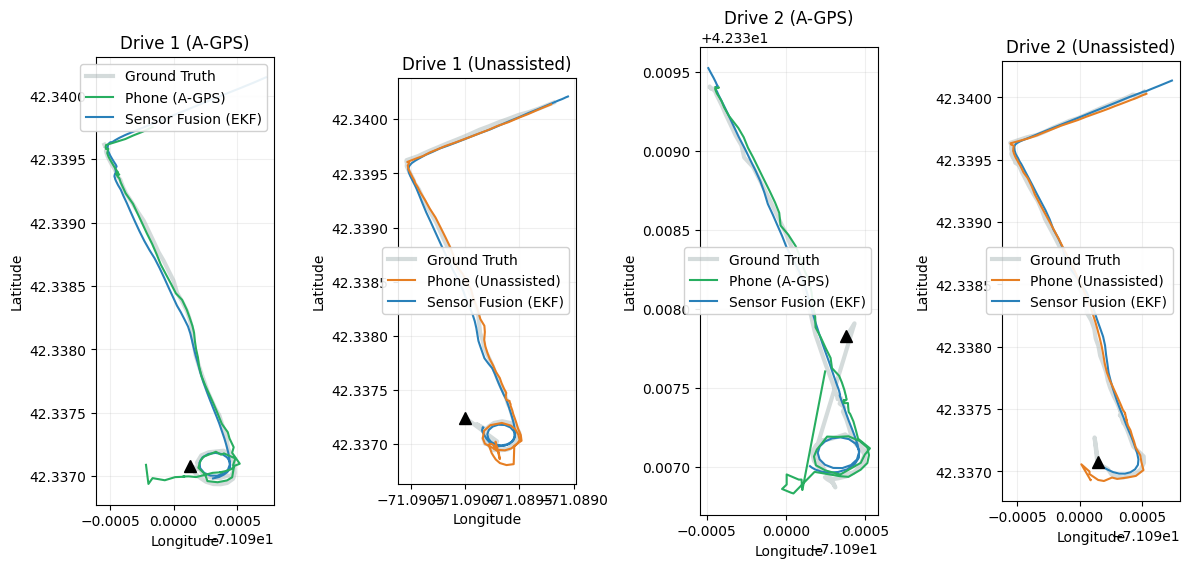

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 10))
axes = axes.flatten()
for i in range(4):
    r = drive_results[i]
    ax = axes[i]
    # Ground truth
    ax.plot([d['lon'] for d in r['gt'] if d['t'] <= WINDOW],
            [d['lat'] for d in r['gt'] if d['t'] <= WINDOW],
            '-', color=C_GT, lw=3, alpha=0.4,
            label='Ground Truth', zorder=1)
    # Phone
    c = C_AGPS if r['condition'] == 'agps_on' else C_UNASSISTED
    lbl = 'Phone (A-GPS)' if r['condition'] == 'agps_on' else 'Phone (Unassisted)'
    ax.plot([d['lon'] for d in r['phone'] if d['t'] <= WINDOW],
            [d['lat'] for d in r['phone'] if d['t'] <= WINDOW],
            '-', color=c, lw=1.5,
            label=lbl, zorder=3)
    # EKF
    if r['ekf']:
        ax.plot([d['lon'] for d in r['ekf'] if d['t'] <= WINDOW],
                [d['lat'] for d in r['ekf'] if d['t'] <= WINDOW],
                '-', color=C_EKF, lw=1.5,
                label='Sensor Fusion (EKF)', zorder=2)
    # Start point
    if r['gt']:
        ax.plot(r['gt'][0]['lon'], r['gt'][0]['lat'], 'k^', ms=8, zorder=4)
    # Formatting per subplot
    ax.set_title(r['name'])
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)
    ax.legend(framealpha=0.9)
plt.tight_layout()
plt.savefig("plots_jh/traj_grid.png", dpi=150)
plt.show()
plt.close()

### Full Trajectories

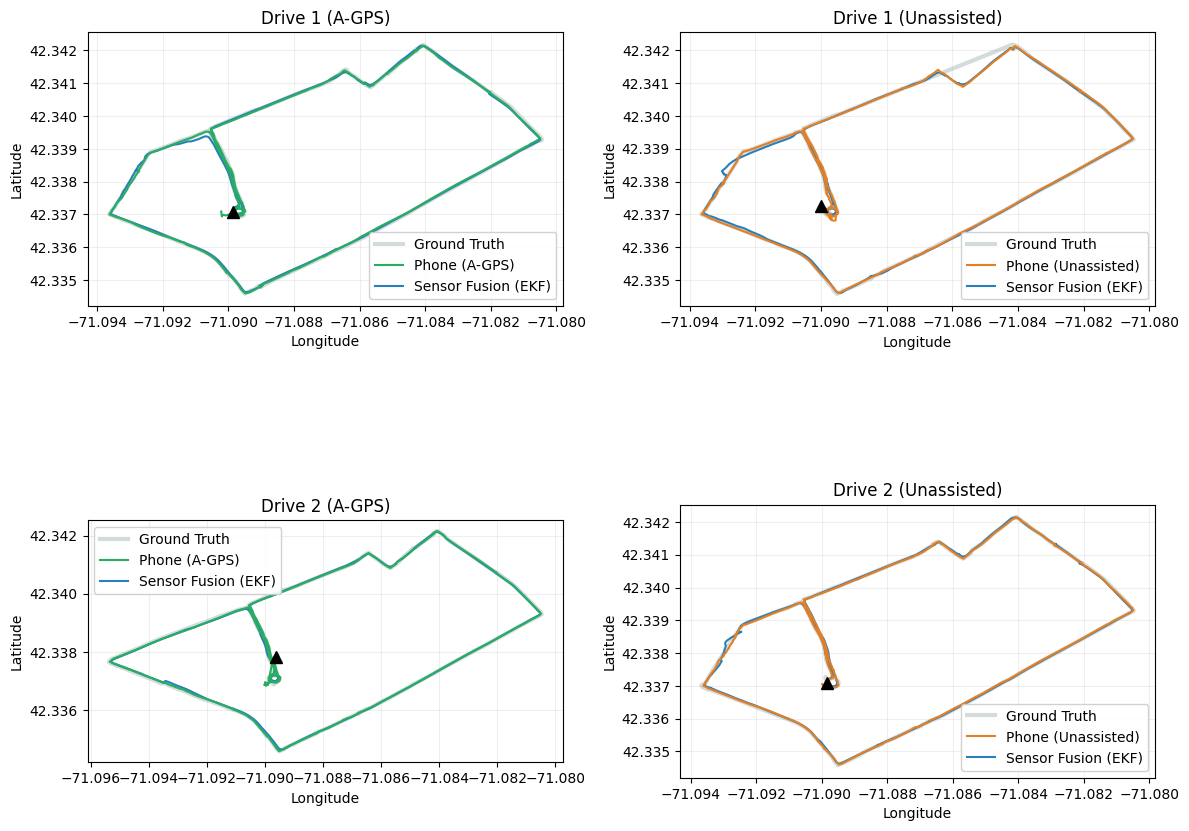

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for i in range(4):
    r = drive_results[i]
    ax = axes[i]
    ax.plot([d['lon'] for d in r['gt']], [d['lat'] for d in r['gt']],
            '-', color=C_GT, lw=3, alpha=0.4, label='Ground Truth', zorder=1)
    c = C_AGPS if r['condition'] == 'agps_on' else C_UNASSISTED
    lbl = 'Phone (A-GPS)' if r['condition'] == 'agps_on' else 'Phone (Unassisted)'
    ax.plot([d['lon'] for d in r['phone']], [d['lat'] for d in r['phone']],
            '-', color=c, lw=1.5, label=lbl, zorder=3)
    if r['ekf']:
        ax.plot([d['lon'] for d in r['ekf']], [d['lat'] for d in r['ekf']],
                '-', color=C_EKF, lw=1.5, label='Sensor Fusion (EKF)', zorder=2)
    if r['gt']:
        ax.plot(r['gt'][0]['lon'], r['gt'][0]['lat'], 'k^', ms=8, zorder=4)
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.set_title(r['name']); ax.legend(framealpha=0.9)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.2)
plt.tight_layout()
#     plt.savefig(f"plots_jh/traj_{r['name'].replace(' ','_')}.png", dpi=150)
plt.show(); plt.close()

---
## Driving — Mean Spatial Error Over Runs (GT-anchored time axis)

Consolidates per-condition by averaging error across runs at each time step.
Time axis starts at ground-truth collection start so TTFF gap is visible.

In [ ]:
def resample_to_grid(errors, dt_key, t_max, dt_step=1.0):
    """Resample an error time series onto a uniform grid by nearest-neighbor."""
    if len(errors) == 0:
        return np.full(int(t_max / dt_step) + 1, np.nan)
    t_arr = np.array([e[dt_key] for e in errors])
    err_arr = np.array([e['err'] for e in errors])
    grid = np.arange(0, t_max + dt_step, dt_step)
    out = np.full_like(grid, np.nan)
    for i, t in enumerate(grid):
        if t < t_arr[0] or t > t_arr[-1]:
            continue
        idx = np.argmin(np.abs(t_arr - t))
        out[i] = err_arr[idx]
    return out

In [63]:
# Build resampled arrays for each condition (phone spatial, GT-anchored time)
drive_on = [r for r in drive_results if r['condition'] == 'agps_on']
drive_off = [r for r in drive_results if r['condition'] == 'unassisted']

grid_t = np.arange(0, WINDOW + 1, 1.0)

agps_spatial = np.array([resample_to_grid(r['err_phone'], 'dt', WINDOW) for r in drive_on])
unass_spatial = np.array([resample_to_grid(r['err_phone'], 'dt', WINDOW) for r in drive_off])
ekf_spatial = np.array([resample_to_grid(r['err_ekf'], 'dt', WINDOW) for r in drive_results])

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    agps_mean_sp = np.nanmean(agps_spatial, axis=0)
    agps_std_sp  = np.nanstd(agps_spatial, axis=0)
    unass_mean_sp = np.nanmean(unass_spatial, axis=0)
    unass_std_sp  = np.nanstd(unass_spatial, axis=0)
    ekf_mean_sp = np.nanmean(ekf_spatial, axis=0)
    ekf_std_sp  = np.nanstd(ekf_spatial, axis=0)

In [64]:
# Determine shared y-axis limit across all spatial subplots
y_max_spatial = np.nanmax([
    np.nanmax(agps_mean_sp + agps_std_sp),
    np.nanmax(unass_mean_sp + unass_std_sp),
    np.nanmax(ekf_mean_sp + agps_std_sp),
    np.nanmax(ekf_mean_sp + unass_std_sp),
]) * 1.1

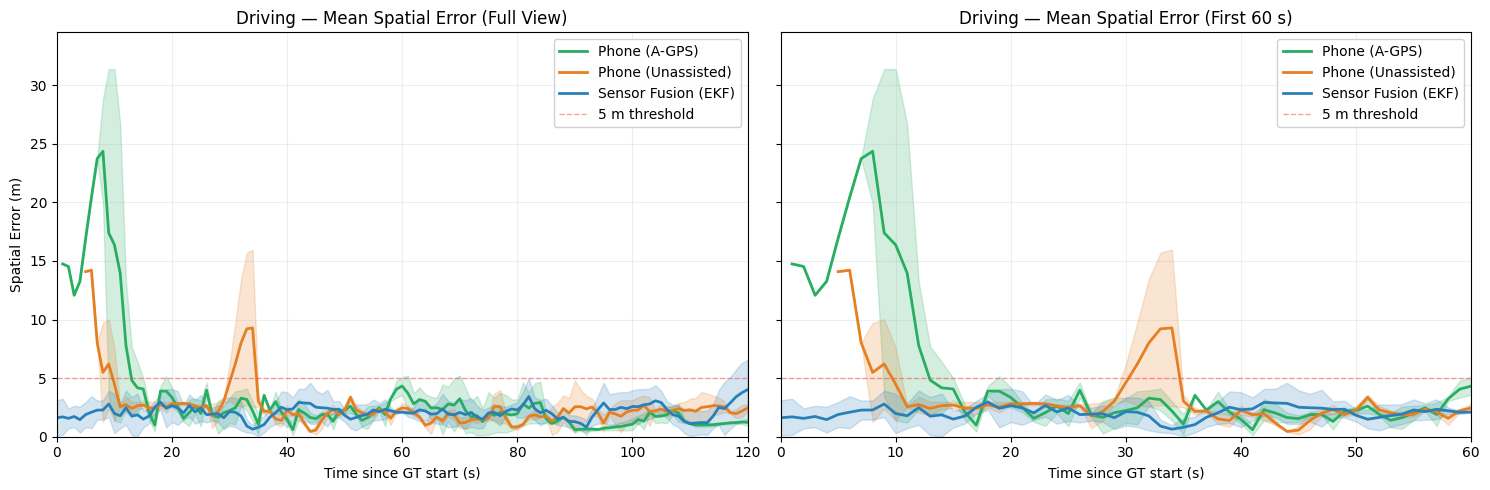

In [69]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# --- Full view ---
ax1.plot(grid_t, agps_mean_sp, color=C_AGPS, lw=2, label='Phone (A-GPS)')
ax1.fill_between(grid_t, agps_mean_sp - agps_std_sp, agps_mean_sp + agps_std_sp,
                 color=C_AGPS, alpha=0.2)
ax1.plot(grid_t, unass_mean_sp, color=C_UNASSISTED, lw=2, label='Phone (Unassisted)')
ax1.fill_between(grid_t, unass_mean_sp - unass_std_sp, unass_mean_sp + unass_std_sp,
                 color=C_UNASSISTED, alpha=0.2)
ax1.plot(grid_t, ekf_mean_sp, color=C_EKF, lw=2, label='Sensor Fusion (EKF)')
ax1.fill_between(grid_t, ekf_mean_sp - ekf_std_sp, ekf_mean_sp + ekf_std_sp,
                 color=C_EKF, alpha=0.2)

ax1.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
ax1.set_xlabel('Time since GT start (s)')
ax1.set_ylabel('Spatial Error (m)')
ax1.set_title('Driving — Mean Spatial Error (Full View)')
ax1.set_xlim(0, WINDOW)
ax1.set_ylim(0, y_max_spatial)
ax1.legend(framealpha=0.9)
ax1.grid(True, alpha=0.2)

# --- Zoomed view ---
ax2.plot(grid_t, agps_mean_sp, color=C_AGPS, lw=2, label='Phone (A-GPS)')
ax2.fill_between(grid_t, agps_mean_sp - agps_std_sp, agps_mean_sp + agps_std_sp,
                 color=C_AGPS, alpha=0.2)

ax2.plot(grid_t, unass_mean_sp, color=C_UNASSISTED, lw=2, label='Phone (Unassisted)')
ax2.fill_between(grid_t, unass_mean_sp - unass_std_sp, unass_mean_sp + unass_std_sp,
                 color=C_UNASSISTED, alpha=0.2)
ax2.plot(grid_t, ekf_mean_sp, color=C_EKF, lw=2, label='Sensor Fusion (EKF)')
ax2.fill_between(grid_t, ekf_mean_sp - ekf_std_sp, ekf_mean_sp + ekf_std_sp,
                 color=C_EKF, alpha=0.2)

ax2.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
ax2.set_xlabel('Time since GT start (s)')
ax2.set_title('Driving — Mean Spatial Error (First 60 s)')
ax2.set_xlim(0, ZOOM)
ax2.set_ylim(0, y_max_spatial)
ax2.legend(framealpha=0.9)
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig("plots_jh/driving_mean_spatial_error.png", dpi=150)
plt.show()
plt.close()

---
## Driving — Mean Time-Synced Error

Unlike spatial matching (nearest point by position), this matches by
absolute timestamp — so it captures along-track lag as well as
cross-track offset.

In [70]:
agps_tsync = np.array([resample_to_grid(r['err_phone_tsync'], 'dt', TIME_SYNC_WINDOW)
                        for r in drive_on])
unass_tsync = np.array([resample_to_grid(r['err_phone_tsync'], 'dt', TIME_SYNC_WINDOW)
                         for r in drive_off])
ekf_tsync = np.array([resample_to_grid(r['err_ekf_tsync'], 'dt', TIME_SYNC_WINDOW)
                         for r in drive_results])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    agps_mean_ts  = np.nanmean(agps_tsync, axis=0)
    agps_std_ts   = np.nanstd(agps_tsync, axis=0)
    unass_mean_ts = np.nanmean(unass_tsync, axis=0)
    unass_std_ts  = np.nanstd(unass_tsync, axis=0)
    ekf_mean_ts = np.nanmean(ekf_tsync, axis=0)
    ekf_std_ts  = np.nanstd(ekf_tsync, axis=0)

grid_ts = np.arange(0, TIME_SYNC_WINDOW + 1, 1.0)

# Shared y-axis limit for time-synced plots
y_max_tsync = np.nanmax([
    np.nanmax(agps_mean_ts + agps_std_ts),
    np.nanmax(unass_mean_ts + unass_std_ts),
    np.nanmax(ekf_mean_ts + ekf_std_ts),
]) * 1.1

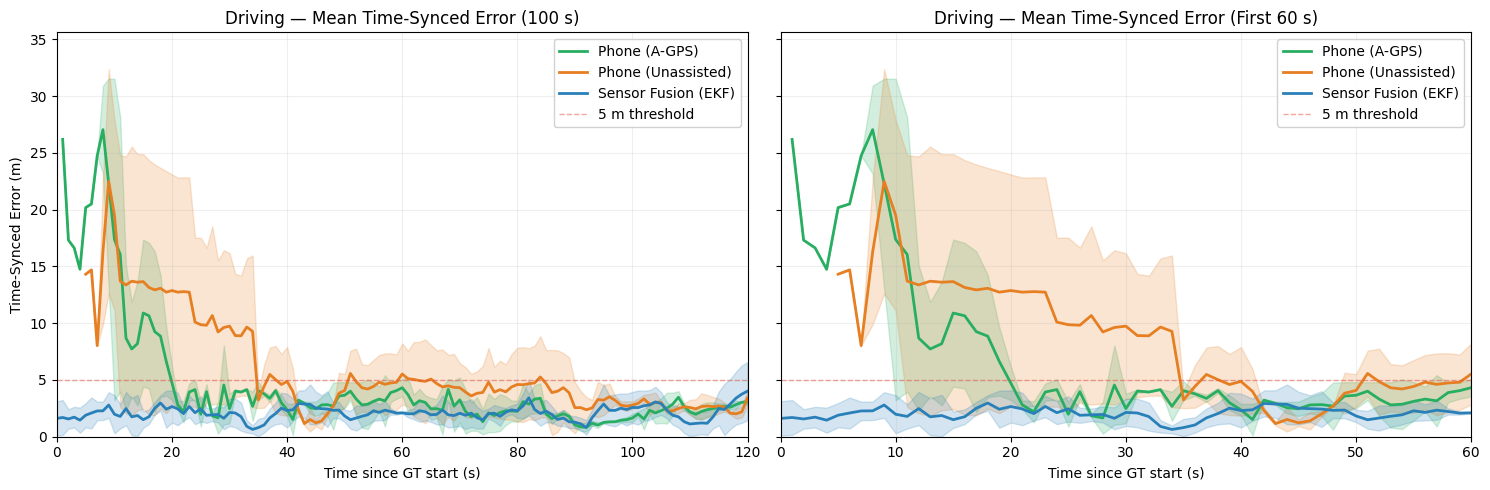

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# --- Full view ---
ax1.plot(grid_ts, agps_mean_ts, color=C_AGPS, lw=2, label='Phone (A-GPS)')
ax1.fill_between(grid_ts, agps_mean_ts - agps_std_ts, agps_mean_ts + agps_std_ts,
                 color=C_AGPS, alpha=0.2)
ax1.plot(grid_ts, unass_mean_ts, color=C_UNASSISTED, lw=2, label='Phone (Unassisted)')
ax1.fill_between(grid_ts, unass_mean_ts - unass_std_ts, unass_mean_ts + unass_std_ts,
                 color=C_UNASSISTED, alpha=0.2)
ax1.plot(grid_ts, ekf_mean_ts, color=C_EKF, lw=2, label='Sensor Fusion (EKF)')
ax1.fill_between(grid_ts, ekf_mean_ts - ekf_std_ts, ekf_mean_ts + ekf_std_ts,
                 color=C_EKF, alpha=0.2)

ax1.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
ax1.set_xlabel('Time since GT start (s)')
ax1.set_ylabel('Time-Synced Error (m)')
ax1.set_title('Driving — Mean Time-Synced Error (100 s)')
ax1.set_xlim(0, TIME_SYNC_WINDOW)
ax1.set_ylim(0, y_max_tsync)
ax1.legend(framealpha=0.9)
ax1.grid(True, alpha=0.2)

# --- Zoomed view ---
ax2.plot(grid_ts, agps_mean_ts, color=C_AGPS, lw=2, label='Phone (A-GPS)')
ax2.fill_between(grid_ts, agps_mean_ts - agps_std_ts, agps_mean_ts + agps_std_ts,
                 color=C_AGPS, alpha=0.2)
ax2.plot(grid_ts, unass_mean_ts, color=C_UNASSISTED, lw=2, label='Phone (Unassisted)')
ax2.fill_between(grid_ts, unass_mean_ts - unass_std_ts, unass_mean_ts + unass_std_ts,
                 color=C_UNASSISTED, alpha=0.2)
ax2.plot(grid_ts, ekf_mean_ts, color=C_EKF, lw=2, label='Sensor Fusion (EKF)')
ax2.fill_between(grid_ts, ekf_mean_ts - ekf_std_ts, ekf_mean_ts + ekf_std_ts,
                 color=C_EKF, alpha=0.2)

ax2.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
ax2.set_xlabel('Time since GT start (s)')
ax2.set_title('Driving — Mean Time-Synced Error (First 60 s)')
ax2.set_xlim(0, 60)
ax2.set_ylim(0, y_max_tsync)
ax2.legend(framealpha=0.9)
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig("plots_jh/driving_mean_timesynced_error.png", dpi=150)
plt.show()
plt.close()

---
## Driving — Summary Bar Chart

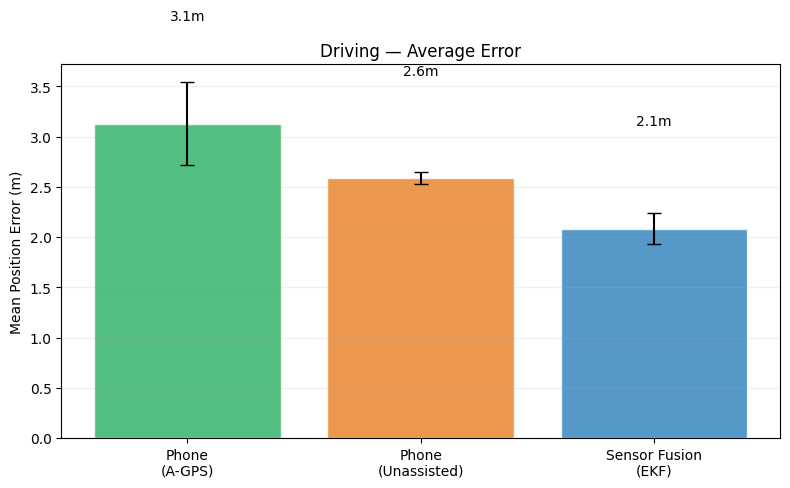

In [58]:
fig, ax = plt.subplots(figsize=(8, 5))
labels = ['Phone\n(A-GPS)', 'Phone\n(Unassisted)', 'Sensor Fusion\n(EKF)']
means = [
    np.mean([r['mean_phone'] for r in drive_on if r['mean_phone'] is not None]),
    np.mean([r['mean_phone'] for r in drive_off if r['mean_phone'] is not None]),
    np.mean([r['mean_ekf'] for r in drive_results if r['mean_ekf'] is not None]),
]
stds = [
    np.std([r['mean_phone'] for r in drive_on if r['mean_phone'] is not None]),
    np.std([r['mean_phone'] for r in drive_off if r['mean_phone'] is not None]),
    np.std([r['mean_ekf'] for r in drive_results if r['mean_ekf'] is not None]),
]
colors = [C_AGPS, C_UNASSISTED, C_EKF]
x = np.arange(len(labels))
bars = ax.bar(x, means, yerr=stds, capsize=5, color=colors, alpha=0.8, edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('Mean Position Error (m)')
ax.set_title('Driving — Average Error')
ax.grid(True, alpha=0.2, axis='y')
for bar, val in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.1f}m', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig("plots_jh/driving_summary.png", dpi=150)
plt.show(); plt.close()

---
## Driving — Error Box Plot

C:\Users\horwi\AppData\Local\Temp\ipykernel_31444\497314639.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([errs_on, errs_off, errs_ekf],


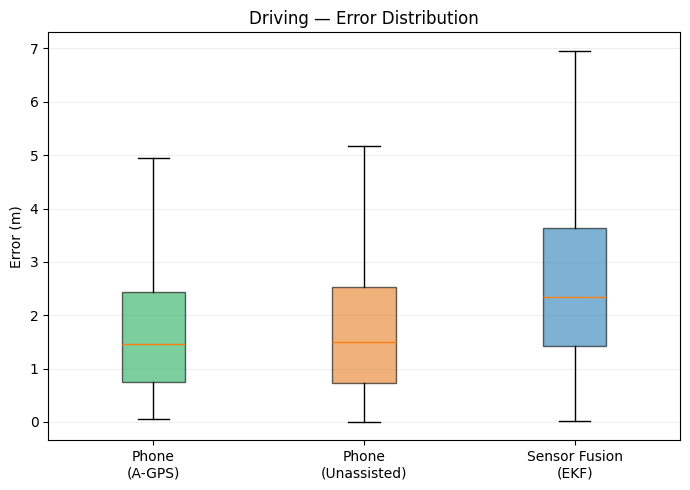

In [57]:
# errs_on = [e['err'] for r in drive_results if r['condition'] == 'agps_on'
#            for e in r['err_phone'] if e['dt'] <= r['cutoff']]
# errs_off = [e['err'] for r in drive_results if r['condition'] == 'unassisted'
#             for e in r['err_phone'] if e['dt'] <= r['cutoff']]
# errs_ekf = [e['err'] for r in drive_results for e in r['err_ekf'] if e['dt'] <= r['cutoff']]
errs_on = [e['err'] for r in drive_results if r['condition'] == 'agps_on'
           for e in r['err_phone']]
errs_off = [e['err'] for r in drive_results if r['condition'] == 'unassisted'
            for e in r['err_phone']]
errs_ekf = [e['err'] for r in drive_results for e in r['err_ekf']]
fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot([errs_on, errs_off, errs_ekf],
                labels=['Phone\n(A-GPS)', 'Phone\n(Unassisted)', 'Sensor Fusion\n(EKF)'],
                patch_artist=True, showfliers=False)
for patch, col in zip(bp['boxes'], [C_AGPS, C_UNASSISTED, C_EKF]):
    patch.set_facecolor(col); patch.set_alpha(0.6)
ax.set_ylabel('Error (m)')
ax.set_title('Driving — Error Distribution')
ax.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.savefig("plots_jh/driving_boxplot.png", dpi=150)
plt.show(); plt.close()

---
## Stationary — Mean Convergence (IMU-start anchored, averaged over runs)

Time axis starts at first IMU timestamp from the ROS bag, so the gap
before the phone or GPS first fix shows the TTFF.

In [ ]:
stat_phone_on  = np.array([resample_to_grid(r['err_phone'], 'dt', WINDOW) for r in stat_on])
stat_phone_off = np.array([resample_to_grid(r['err_phone'], 'dt', WINDOW) for r in stat_off])
stat_gps_all   = np.array([resample_to_grid(r['err_gps'], 'dt', WINDOW) for r in stat_results])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    s_on_mean  = np.nanmean(stat_phone_on, axis=0)
    s_on_std   = np.nanstd(stat_phone_on, axis=0)
    s_off_mean = np.nanmean(stat_phone_off, axis=0)
    s_off_std  = np.nanstd(stat_phone_off, axis=0)
    s_gps_mean = np.nanmean(stat_gps_all, axis=0)
    s_gps_std  = np.nanstd(stat_gps_all, axis=0)

grid_stat = np.arange(0, WINDOW + 1, 1.0)

y_max_stat = np.nanmax([
    np.nanmax(s_on_mean + s_on_std),
    np.nanmax(s_off_mean + s_off_std),
    np.nanmax(s_gps_mean + s_gps_std),
]) * 1.1

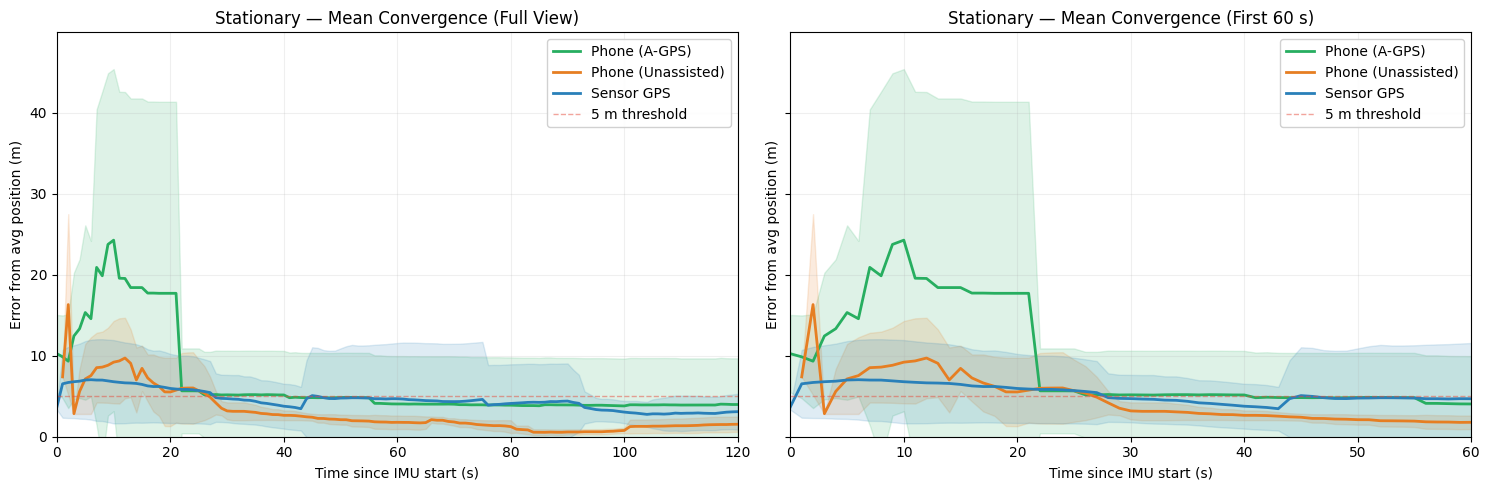

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax in [ax1, ax2]:
    full_grid_stat = np.arange(0, np.min())
    ax.plot(grid_stat, s_on_mean, color=C_AGPS, lw=2, label='Phone (A-GPS)')
    ax.fill_between(grid_stat, s_on_mean - s_on_std, s_on_mean + s_on_std,
                    color=C_AGPS, alpha=0.15)
    ax.plot(grid_stat, s_off_mean, color=C_UNASSISTED, lw=2, label='Phone (Unassisted)')
    ax.fill_between(grid_stat, s_off_mean - s_off_std, s_off_mean + s_off_std,
                    color=C_UNASSISTED, alpha=0.15)
    ax.plot(grid_stat, s_gps_mean, color=C_EKF, lw=2, label='Sensor GPS')
    ax.fill_between(grid_stat, s_gps_mean - s_gps_std, s_gps_mean + s_gps_std,
                    color=C_EKF, alpha=0.15)
    ax.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
    ax.set_xlabel('Time since IMU start (s)'); ax.set_ylabel('Error from avg position (m)')
    ax.legend(framealpha=0.9); ax.grid(True, alpha=0.2)

ax1.set_xlim(0, WINDOW);  ax1.set_ylim(0, y_max_stat)
ax1.set_title('Stationary — Mean Convergence (Full View)')
ax2.set_xlim(0, ZOOM);    ax2.set_ylim(0, y_max_stat)
ax2.set_title('Stationary — Mean Convergence (First 60 s)')

plt.tight_layout()
plt.savefig("plots_jh/stationary_mean_convergence.png", dpi=150)
plt.show(); plt.close()

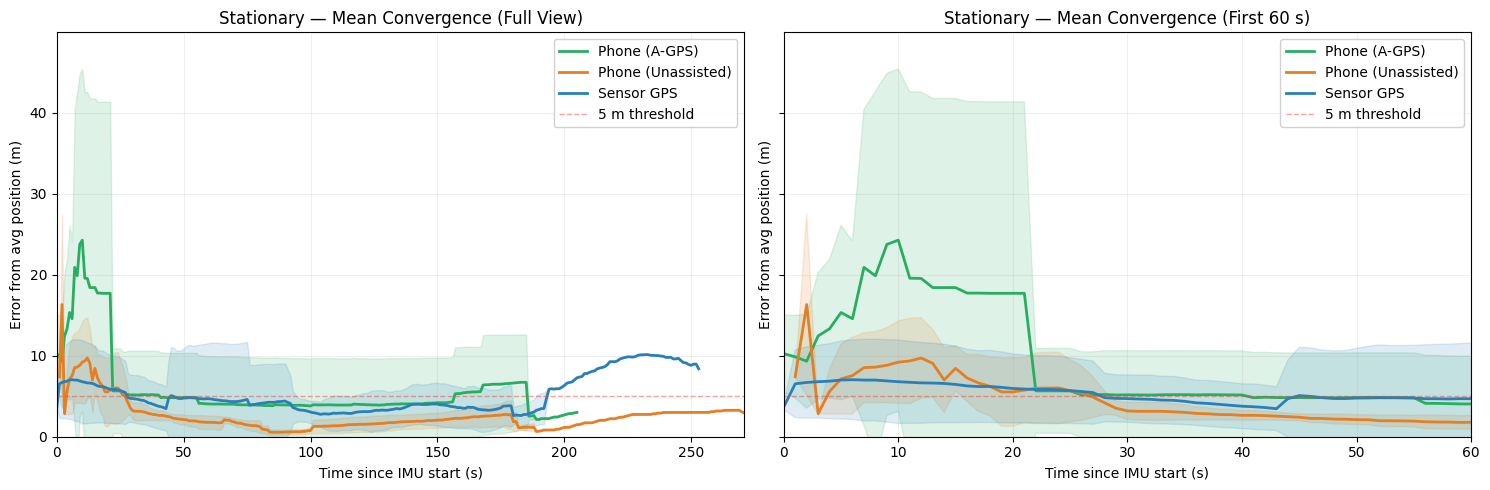

In [53]:
# --- Compute maximum available duration across all runs ---
max_len = int(np.nanmax([
    max(d['dt'] for d in r['err_phone']) for r in stat_results
]))

# --- Resample all series to the same dynamic max length ---
stat_phone_on  = np.array([resample_to_grid(r['err_phone'], 'dt', max_len) for r in stat_on])
stat_phone_off = np.array([resample_to_grid(r['err_phone'], 'dt', max_len) for r in stat_off])
stat_gps_all   = np.array([resample_to_grid(r['err_gps'], 'dt', max_len) for r in stat_results])

# --- Compute mean and std (ignoring NaNs) ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    s_on_mean  = np.nanmean(stat_phone_on, axis=0)
    s_on_std   = np.nanstd(stat_phone_on, axis=0)
    s_off_mean = np.nanmean(stat_phone_off, axis=0)
    s_off_std  = np.nanstd(stat_phone_off, axis=0)
    s_gps_mean = np.nanmean(stat_gps_all, axis=0)
    s_gps_std  = np.nanstd(stat_gps_all, axis=0)

# --- Time grid based on max_len ---
grid_stat = np.arange(0, max_len + 1, 1.0)

# --- Y-axis upper bound ---
y_max_stat = np.nanmax([
    np.nanmax(s_on_mean + s_on_std),
    np.nanmax(s_off_mean + s_off_std),
    np.nanmax(s_gps_mean + s_gps_std),
]) * 1.1

# --- Plot (full + zoom view) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax in [ax1, ax2]:
    ax.plot(grid_stat, s_on_mean, color=C_AGPS, lw=2, label='Phone (A-GPS)')
    ax.fill_between(grid_stat, s_on_mean - s_on_std, s_on_mean + s_on_std,
                    color=C_AGPS, alpha=0.15)

    ax.plot(grid_stat, s_off_mean, color=C_UNASSISTED, lw=2, label='Phone (Unassisted)')
    ax.fill_between(grid_stat, s_off_mean - s_off_std, s_off_mean + s_off_std,
                    color=C_UNASSISTED, alpha=0.15)

    ax.plot(grid_stat, s_gps_mean, color=C_EKF, lw=2, label='Sensor GPS')
    ax.fill_between(grid_stat, s_gps_mean - s_gps_std, s_gps_mean + s_gps_std,
                    color=C_EKF, alpha=0.15)

    ax.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
    ax.set_xlabel('Time since IMU start (s)')
    ax.set_ylabel('Error from avg position (m)')
    ax.legend(framealpha=0.9)
    ax.grid(True, alpha=0.2)

# Full view
ax1.set_xlim(0, max_len)
ax1.set_ylim(0, y_max_stat)
ax1.set_title('Stationary — Mean Convergence (Full View)')

# Zoomed view (keep your ZOOM window if desired)
ax2.set_xlim(0, ZOOM)
ax2.set_ylim(0, y_max_stat)
ax2.set_title(f'Stationary — Mean Convergence (First {ZOOM} s)')

plt.tight_layout()
plt.savefig("plots_jh/stationary_mean_convergence.png", dpi=150)
plt.show()
plt.close()

---
## Stationary — Averaged Summary (Median)

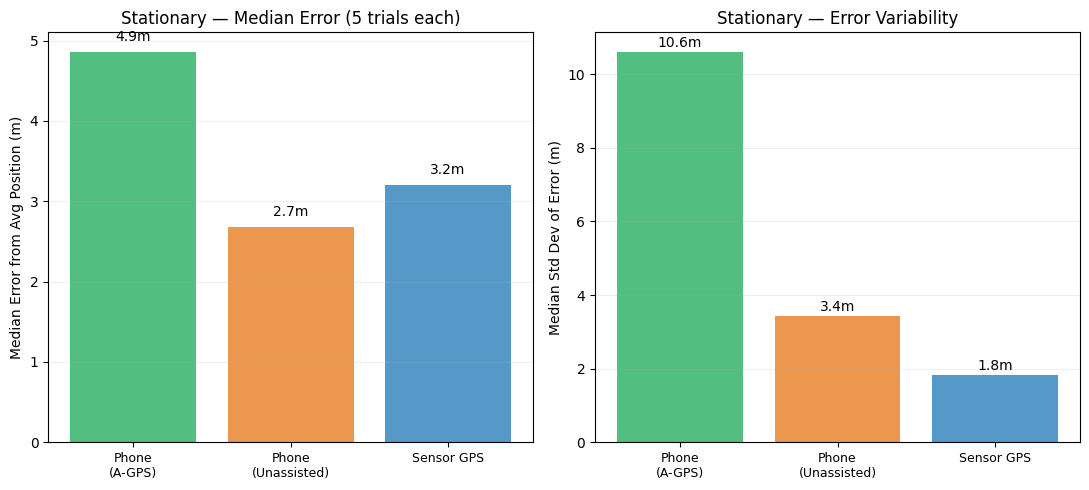

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
labels_s = ['Phone\n(A-GPS)', 'Phone\n(Unassisted)', 'Sensor GPS']
medians_s = [
    np.median([r['mean_phone'] for r in stat_on if r['mean_phone'] is not None]),
    np.median([r['mean_phone'] for r in stat_off if r['mean_phone'] is not None]),
    np.median([r['mean_gps'] for r in stat_results if r['mean_gps'] is not None]),
]
stds_med = [
    np.median([r['std_phone'] for r in stat_on if r['std_phone'] is not None]),
    np.median([r['std_phone'] for r in stat_off if r['std_phone'] is not None]),
    np.median([r['std_gps'] for r in stat_results if r['std_gps'] is not None]),
]
colors_s = [C_AGPS, C_UNASSISTED, C_EKF]
x = np.arange(len(labels_s))

bars = ax1.bar(x, medians_s, color=colors_s, alpha=0.8)
ax1.set_xticks(x); ax1.set_xticklabels(labels_s, fontsize=9)
ax1.set_ylabel('Median Error from Avg Position (m)')
ax1.set_title('Stationary — Median Error (5 trials each)')
ax1.grid(True, alpha=0.2, axis='y')
for bar, val in zip(bars, medians_s):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{val:.1f}m', ha='center', va='bottom', fontsize=10)

bars2 = ax2.bar(x, stds_med, color=colors_s, alpha=0.8)
ax2.set_xticks(x); ax2.set_xticklabels(labels_s, fontsize=9)
ax2.set_ylabel('Median Std Dev of Error (m)')
ax2.set_title('Stationary — Error Variability')
ax2.grid(True, alpha=0.2, axis='y')
for bar, val in zip(bars2, stds_med):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             f'{val:.1f}m', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig("plots_jh/stationary_summary.png", dpi=150)
plt.show(); plt.close()

---
## Stationary — Box Plot

C:\Users\horwi\AppData\Local\Temp\ipykernel_31444\1280057360.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([serrs_on, serrs_off, serrs_gps],


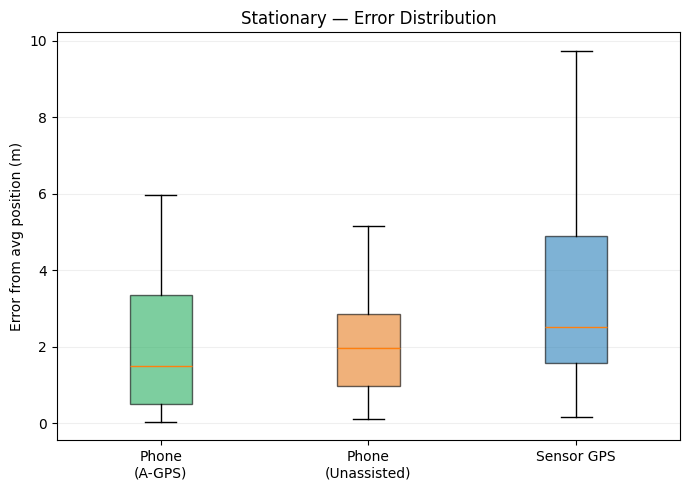

In [46]:
serrs_on = [e['err'] for r in stat_on for e in r['err_phone'] if e['dt'] <= WINDOW]
serrs_off = [e['err'] for r in stat_off for e in r['err_phone'] if e['dt'] <= WINDOW]
serrs_gps = [e['err'] for r in stat_results for e in r['err_gps'] if e['dt'] <= WINDOW]

fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot([serrs_on, serrs_off, serrs_gps],
                labels=['Phone\n(A-GPS)', 'Phone\n(Unassisted)', 'Sensor GPS'],
                patch_artist=True, showfliers=False)
for patch, col in zip(bp['boxes'], [C_AGPS, C_UNASSISTED, C_EKF]):
    patch.set_facecolor(col); patch.set_alpha(0.6)
ax.set_ylabel('Error from avg position (m)')
ax.set_title('Stationary — Error Distribution')
ax.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.savefig("plots_jh/stationary_boxplot.png", dpi=150)
plt.show(); plt.close()

---
## Combined — Side-by-Side Trajectory (Drive 2)

In [47]:
d2_agps = next((r for r in drive_results if r['name'] == 'Drive 2 (A-GPS)'), None)
d2_unassisted = next((r for r in drive_results if r['name'] == 'Drive 2 (Unassisted)'), None)

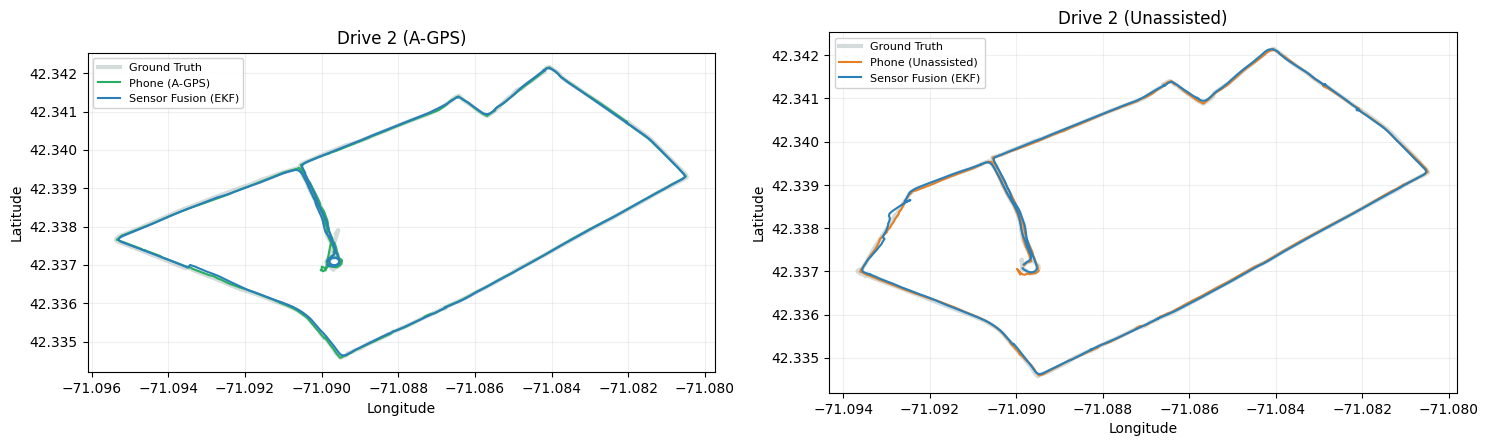

In [48]:
if d2_agps and d2_unassisted:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

    for ax, r, c, lbl in [(ax1, d2_agps, C_AGPS, 'Phone (A-GPS)'),
                           (ax2, d2_unassisted, C_UNASSISTED, 'Phone (Unassisted)')]:
        ax.plot([d['lon'] for d in r['gt']], [d['lat'] for d in r['gt']],
                '-', color=C_GT, lw=3, alpha=0.4, label='Ground Truth')
        ax.plot([d['lon'] for d in r['phone']], [d['lat'] for d in r['phone']],
                '-', color=c, lw=1.5, label=lbl)
        if r['ekf']:
            ax.plot([d['lon'] for d in r['ekf']], [d['lat'] for d in r['ekf']],
                    '-', color=C_EKF, lw=1.5, label='Sensor Fusion (EKF)')
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
        ax.set_title(r['name']); ax.legend(framealpha=0.9, fontsize=8)
        ax.set_aspect('equal'); ax.grid(True, alpha=0.2)

    plt.tight_layout()
    plt.savefig("plots_jh/combined_trajectory.png", dpi=150)
    plt.show(); plt.close()

---
## Combined — All Systems Error Overlay (Drive 2, GT-anchored)

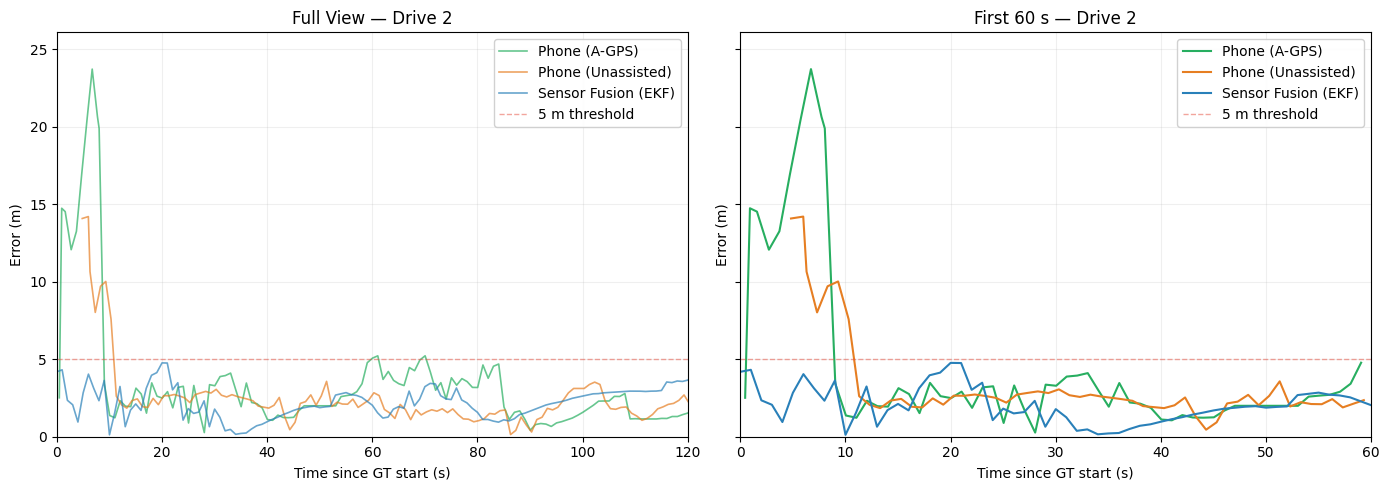

In [54]:
if d2_agps and d2_unassisted:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

    # Collect all y values for shared axis
    all_errs_full = []

    # Full view
    if d2_agps['err_phone']:
        t_ph = [e['dt'] for e in d2_agps['err_phone']]
        e_ph = [e['err'] for e in d2_agps['err_phone']]
        ax1.plot(t_ph, e_ph, '-', color=C_AGPS, alpha=0.7, lw=1.2, label='Phone (A-GPS)')
        all_errs_full.extend(e_ph)
    if d2_unassisted['err_phone']:
        t_ph = [e['dt'] for e in d2_unassisted['err_phone']]
        e_ph = [e['err'] for e in d2_unassisted['err_phone']]
        ax1.plot(t_ph, e_ph, '-', color=C_UNASSISTED, alpha=0.7, lw=1.2, label='Phone (Unassisted)')
        all_errs_full.extend(e_ph)
    if d2_agps['err_ekf']:
        ax1.plot([e['dt'] for e in d2_agps['err_ekf']], [e['err'] for e in d2_agps['err_ekf']],
                 '-', color=C_EKF, alpha=0.7, lw=1.2, label='Sensor Fusion (EKF)')
        all_errs_full.extend([e['err'] for e in d2_agps['err_ekf']])
    ax1.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
    ax1.set_xlabel('Time since GT start (s)'); ax1.set_ylabel('Error (m)')
    ax1.set_title('Full View — Drive 2'); ax1.legend(framealpha=0.9)
    ax1.set_xlim(0, WINDOW); ax1.grid(True, alpha=0.2)

    # Zoomed first 60s
    for data, c, lbl in [(d2_agps['err_phone'], C_AGPS, 'Phone (A-GPS)'),
                          (d2_unassisted['err_phone'], C_UNASSISTED, 'Phone (Unassisted)'),
                          (d2_agps['err_ekf'], C_EKF, 'Sensor Fusion (EKF)')]:
        zoom = [e for e in data if e['dt'] <= ZOOM]
        if zoom:
            ax2.plot([e['dt'] for e in zoom], [e['err'] for e in zoom],
                     '-', color=c, lw=1.5, label=lbl)
    ax2.axhline(THRESHOLD, color='#e74c3c', ls='--', lw=1, alpha=0.5, label='5 m threshold')
    ax2.set_xlabel('Time since GT start (s)'); ax2.set_ylabel('Error (m)')
    ax2.set_title('First 60 s — Drive 2'); ax2.legend(framealpha=0.9)
    ax2.set_xlim(0, ZOOM); ax2.grid(True, alpha=0.2)

    # Match y-axes
    y_max_combined = max(all_errs_full) * 1.1 if all_errs_full else 50
    ax1.set_ylim(0, y_max_combined)

    plt.tight_layout()
    plt.savefig("plots_jh/combined_error_overlay.png", dpi=150)
    plt.show(); plt.close()

---
## Summary Tables

In [55]:
print("\n" + "=" * 90)
print("  DRIVING RESULTS (spatial matching)")
print("=" * 90)
print(f"  {'Trial':<24} | {'Mean Ph':>8} | {'Std Ph':>7} | {'Mean EKF':>8} | {'Std EKF':>7} | {'1st Ph':>7} | {'1st EKF':>8} | {'Window':>6}")
print("-" * 90)
for r in drive_results:
    mp = f"{r['mean_phone']:.1f}m" if r['mean_phone'] else "N/A"
    sp = f"{r['std_phone']:.1f}m" if r['std_phone'] else "N/A"
    me = f"{r['mean_ekf']:.1f}m" if r['mean_ekf'] else "N/A"
    se = f"{r['std_ekf']:.1f}m" if r['std_ekf'] else "N/A"
    fp = f"{r['first_phone']:.1f}m" if r['first_phone'] else "N/A"
    fe = f"{r['first_ekf']:.1f}m" if r['first_ekf'] else "N/A"
    w = f"{r['cutoff']}s"
    print(f"  {r['name']:<24} | {mp:>8} | {sp:>7} | {me:>8} | {se:>7} | {fp:>7} | {fe:>8} | {w:>6}")
print("=" * 90)


  DRIVING RESULTS (spatial matching)
  Trial                    |  Mean Ph |  Std Ph | Mean EKF | Std EKF |  1st Ph |  1st EKF | Window
------------------------------------------------------------------------------------------
  Drive 1 (A-GPS)          |     2.7m |    4.9m |     2.2m |    1.2m |   28.8m |     0.9m |   120s
  Drive 1 (Unassisted)     |     2.6m |    2.5m |     2.1m |    1.4m |    1.3m |     1.0m |   120s
  Drive 2 (A-GPS)          |     3.5m |    4.2m |     2.2m |    1.0m |    2.5m |     4.2m |   120s
  Drive 2 (Unassisted)     |     2.5m |    2.2m |     1.8m |    1.2m |   14.1m |     0.4m |   120s


In [56]:
print("\n" + "=" * 65)
print("  STATIONARY RESULTS (median of 5 trials)")
print("=" * 65)
print(f"  {'Condition':<20} | {'Med Phone':>10} | {'Med Std Ph':>10} | {'Med GPS':>8} | {'Med Std GPS':>11}")
print("-" * 65)
vals_on = [r['mean_phone'] for r in stat_on if r['mean_phone'] is not None]
stds_on = [r['std_phone'] for r in stat_on if r['std_phone'] is not None]
vals_gps_on = [r['mean_gps'] for r in stat_on if r['mean_gps'] is not None]
stds_gps_on = [r['std_gps'] for r in stat_on if r['std_gps'] is not None]
print(f"  {'A-GPS (5 trials)':<20} | {np.median(vals_on):>9.1f}m | {np.median(stds_on):>9.1f}m | {np.median(vals_gps_on):>7.1f}m | {np.median(stds_gps_on):>10.1f}m")
vals_off = [r['mean_phone'] for r in stat_off if r['mean_phone'] is not None]
stds_off = [r['std_phone'] for r in stat_off if r['std_phone'] is not None]
vals_gps_off = [r['mean_gps'] for r in stat_off if r['mean_gps'] is not None]
stds_gps_off = [r['std_gps'] for r in stat_off if r['std_gps'] is not None]
print(f"  {'Unassisted (5 trials)':<20} | {np.median(vals_off):>9.1f}m | {np.median(stds_off):>9.1f}m | {np.median(vals_gps_off):>7.1f}m | {np.median(stds_gps_off):>10.1f}m")
print("=" * 65)


  STATIONARY RESULTS (median of 5 trials)
  Condition            |  Med Phone | Med Std Ph |  Med GPS | Med Std GPS
-----------------------------------------------------------------
  A-GPS (5 trials)     |       4.9m |      10.6m |     3.7m |        2.6m
  Unassisted (5 trials) |       2.7m |       3.4m |     2.7m |        1.8m
